In [2]:
# Install Packages
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import scipy.stats as stats

In [3]:
# Load in tables
athletes = pd.read_csv("../data/athlete_events.csv")
city_coords = pd.read_csv("../data/city_coords.csv")
country_coords = pd.read_csv("../data/country_coords.csv")
noc_regions = pd.read_csv("../data/noc_regions.csv")

In [4]:
# Merge all original tables
df = athletes.merge(
    noc_regions,
    on="NOC",
    how="left"
)
df = df.merge(
    country_coords,
    left_on="region",
    right_on="Country",
    how="left"
)
df = df.rename(columns={
    "Latitude": "country_lat",
    "Longitude": "country_lon"
})
df = df.merge(
    city_coords,
    on="City",
    how="left"
)
df = df.rename(columns={
    "Latitude": "host_lat",
    "Longitude": "host_lon"
})

In [5]:
# Calculate approximate distance between country and host city
df["distance_to_host"] = np.sqrt(
    (69 * (df["country_lat"] - df["host_lat"]))**2 +
    (69 * np.cos(np.radians(df["host_lat"])) * (df["country_lon"] - df["host_lon"]))**2
)
# df.head()

In [6]:
# set weighted medal score
df["Medal"] = df["Medal"].fillna("None")
df["medal_score"] = df["Medal"].map({
    "Gold": 5,
    "Silver": 3,
    "Bronze": 1,
    "None": 0
})
# df.head()

In [7]:
# Group by NOC, medal, games, and event to remove duplicate entries for team sports
event_results = (
    df.groupby(["NOC","Games","Event"], as_index=False)
    .agg(
        Medal=("Medal","first"),
        medal_score=("medal_score","first"),
        distance_to_host=("distance_to_host","first")
    )
)
event_results["won_medal"] = event_results["Medal"] != "None"
# print(len(event_results))
# event_results.head()

In [8]:
country_overall = (
    event_results
    .groupby(["NOC"], as_index=False)
    .agg(
        medals=("won_medal", "sum"),
        medal_score=("medal_score", "sum"),
        events_participated=("Event", "size"),
        distance_to_host=("distance_to_host", "first")
    )
)
country_overall["avg_medals_per_event"] = (
    country_overall["medals"] /
    country_overall["events_participated"]
)

country_overall["avg_score_per_event"] = (
    country_overall["medal_score"] /
    country_overall["events_participated"]
)

# country_overall.head()

In [9]:
country_games = (
    event_results
    .groupby(["NOC","Games"], as_index=False)
    .agg(
        medals=("won_medal","sum"),
        medal_score=("medal_score","sum"),
        events_participated=("Event","size"),
        distance_to_host=("distance_to_host","first")
    )
)

country_games["medals_per_event"] = (
    country_games["medals"] /
    country_games["events_participated"]
)

country_games["score_per_event"] = (
    country_games["medal_score"] /
    country_games["events_participated"]
)
country_games = country_games.merge(
    country_overall[["NOC","avg_medals_per_event","avg_score_per_event"]],
    on="NOC",
    how="left"
)
# country_games.head()

In [10]:
country_games["pct_medals_over_avg"] = (
    (country_games["medals_per_event"] - country_games["avg_medals_per_event"]) /
    country_games["avg_medals_per_event"]
)
country_games["pct_score_over_avg"] = (
    (country_games["score_per_event"] - country_games["avg_score_per_event"]) /
    country_games["avg_score_per_event"]
)
# country_games.head(20)

In [11]:
recent_games = country_games[
    country_games["Games"].isin(["2016 Summer", "2014 Winter", "2012 Summer"])
]

In [18]:
filtered_games = recent_games[recent_games["events_participated"] >= 5]
filtered_games = recent_games[recent_games["avg_medals_per_event"] > 0]
filtered_games.head()

,NOC,Games,medals,medal_score,events_participated,distance_to_host,medals_per_event,score_per_event,avg_medals_per_event,avg_score_per_event,pct_medals_over_avg,pct_score_over_avg
12,AFG,2012 Summer,1,1,6,3074.739856,0.166667,0.166667,0.025974,0.025974,5.416667,5.416667
13,AFG,2016 Summer,0,0,3,7883.580896,0.000000,0.000000,0.025974,0.025974,-1.000000,-1.000000
54,ALG,2012 Summer,1,5,29,1627.548933,0.034483,0.172414,0.031579,0.078947,0.091954,1.183908
55,ALG,2016 Summer,0,0,48,4577.173730,0.000000,0.000000,0.031579,0.078947,-1.000000,-1.000000
138,ARG,2012 Summer,3,9,66,6506.505703,0.045455,0.136364,0.044796,0.126482,0.014706,0.078125


In [24]:
plot_data = filtered_games[
    filtered_games["pct_medals_over_avg"].abs() < 3
].copy()

plot_data["pct_medals_over_avg"] *= 100

plot_data = plot_data[
    plot_data["pct_medals_over_avg"] > -100
]

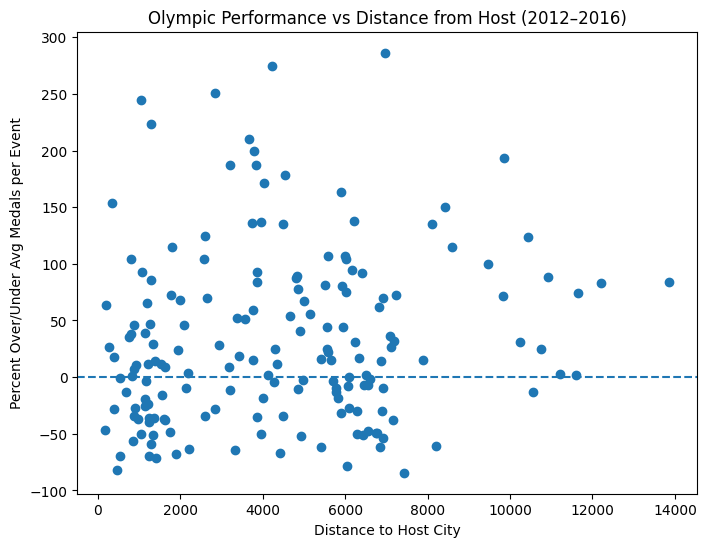

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    plot_data["distance_to_host"],
    plot_data["pct_medals_over_avg"]
)

plt.xlabel("Distance to Host City")
plt.ylabel("Percent Over/Under Avg Medals per Event")
plt.title("Olympic Performance vs Distance from Host (2012–2016)")

plt.show()